# Dall'autovelox scritto all'autovelox appreso

*Coding e Fondamenti di Intelligenza Artificiale · A.A. 2026/27 · Lezione 11*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/cia/blob/main/codice/11/lezione_11.ipynb)

Nel modulo 2 abbiamo scritto a mano la regola dell'autovelox: se superi il limite di non più di 10 km/h paghi 36 €, fino a 40 km/h 148 €, e così via. Oggi facciamo il contrario: diamo a un algoritmo **5.000 multe già emesse** e gli chiediamo di trovare da solo le soglie. È il primo modello di machine learning del corso, ed è anche il primo codice in **Python**.

## 0. Colab in due minuti

Un notebook è fatto di **celle**: celle di testo (come questa) e celle di codice.

- Si esegue una cella con **Shift + Invio**; il risultato compare sotto.
- Le celle si eseguono **dall'alto in basso**: se una cella usa una variabile, la cella che la crea deve essere già stata eseguita. Per ripartire da capo: *Runtime → Esegui tutto*.
- Il notebook gira sui computer di Google: non serve installare niente. Per tenere le vostre modifiche: *File → Salva una copia in Drive*.

## 1. Da R a Python

I concetti sono gli stessi, cambia la sintassi.

| R | Python | |
|---|---|---|
| `x <- 5` | `x = 5` | assegnare |
| `c(120, 80, 45)` | `[120, 80, 45]` | un vettore è una **lista** |
| `x[1]` | `x[0]` | in Python si conta **da 0** |
| `length(x)` | `len(x)` | |
| `function(a, b) { ... }` | `def f(a, b):` e poi il corpo **rientrato** | le graffe diventano indentazione |
| `if (...) {} else if (...) {}` | `if ...:` / `elif ...:` / `else:` | |
| `for (i in 1:n)` | `for i in range(n):` | `range(n)` va da 0 a n − 1 |
| `library(dplyr)` | `import pandas as pd` | |
| `read.csv("file.csv")` | `pd.read_csv("file.csv")` | |
| `df$x` | `df["x"]` | |
| `filter(df, x > 5)` | `df[df["x"] > 5]` | |
| `df %>% count(x)` | `df["x"].value_counts()` | |
| `group_by(g) %>% summarise(m = mean(x))` | `df.groupby("g")["x"].mean()` | |

In [1]:
spese = [120, 80, 45]    # in R: spese <- c(120, 80, 45)
spese[0]                 # il PRIMO elemento: in Python si conta da 0

120

In [2]:
len(spese), sum(spese)

(3, 245)

## 2. La multa scritta a mano

La funzione `multa()` del modulo 2, tradotta riga per riga. Nessuna graffa: il corpo della funzione e di ogni `if` è quello **rientrato** di quattro spazi.

In [3]:
def multa(velocita, limite):
    differenza = velocita - limite
    if differenza <= 0:
        return 0
    elif differenza <= 10:
        return 36
    elif differenza <= 40:
        return 148
    elif differenza <= 60:
        return 370
    else:
        return 500

In [4]:
# I casi limite del modulo 2: 5 e 10 km/h oltre il limite pagano 36, 11 ne paga 148
multa(95, 90), multa(100, 90), multa(101, 90), multa(160, 90)

(36, 36, 148, 500)

## 3. Le multe vere

Il file ha una riga per auto passata davanti all'autovelox: data, targa, velocità, limite e multa pagata. In Colab lo leggiamo direttamente dal sito del corso.

In [5]:
import pandas as pd

autovelox = pd.read_csv("https://www.vincnardelli.com/cia/dati/autovelox.csv")
autovelox.head()

,Data,Targa,Velocita,Limite,Multa
0,2024-01-01,OS758PB,83,90,0
1,2024-01-02,SN534DU,42,130,0
2,2024-01-03,NK520WJ,114,70,370
3,2024-01-04,CM583CE,130,50,500
4,2024-01-05,JW217HZ,104,90,148


In [6]:
autovelox.shape          # righe e colonne: in R nrow() e ncol()

(5000, 5)

In [7]:
autovelox["Multa"].value_counts()      # in R: count(Multa)

Multa
0      2319
148    1111
500     536
370     530
36      504
Name: count, dtype: int64

In [8]:
# La colonna nuova si crea come in R: autovelox$Differenza <- ...
autovelox["Differenza"] = autovelox["Velocita"] - autovelox["Limite"]
autovelox.head()

,Data,Targa,Velocita,Limite,Multa,Differenza
0,2024-01-01,OS758PB,83,90,0,-7
1,2024-01-02,SN534DU,42,130,0,-88
2,2024-01-03,NK520WJ,114,70,370,44
3,2024-01-04,CM583CE,130,50,500,80
4,2024-01-05,JW217HZ,104,90,148,14


La funzione scritta a mano dà davvero le stesse multe del file? La applichiamo a tutte le 5.000 righe con un ciclo `for`, come nel modulo 3.

In [9]:
calcolate = []
for i in range(len(autovelox)):
    calcolate.append(multa(autovelox["Velocita"][i], autovelox["Limite"][i]))

autovelox["Multa_calcolata"] = calcolate
(autovelox["Multa"] == autovelox["Multa_calcolata"]).mean()

np.float64(1.0)

Vale 1: la funzione e il file sono d'accordo su tutte le righe. La media di una colonna di `True`/`False` è la quota di `True`, come la media di una colonna 0/1 in R.

## 4. L'albero impara le soglie

Adesso facciamo finta di non conoscere la regola. Diamo all'algoritmo solo gli esempi:

- **X**: quello che sappiamo di ogni auto (la differenza tra velocità e limite);
- **y**: quello che vogliamo prevedere (la multa).

Un **albero di classificazione** prova tutte le soglie possibili sulla differenza, sceglie quella che separa meglio le multe, e ripete su ognuno dei due gruppi. In scikit-learn ogni modello si usa allo stesso modo: si crea, si allena con `fit`, si usa con `predict`.

In [10]:
from sklearn.tree import DecisionTreeClassifier, export_text

X = autovelox[["Differenza"]]     # doppie quadre: una tabella con una colonna
y = autovelox["Multa"]            # quadre singole: una colonna

albero = DecisionTreeClassifier(random_state=1)
albero.fit(X, y)

print(export_text(albero, feature_names=["Differenza"]))

|--- Differenza <= 0.50
|   |--- class: 0
|--- Differenza >  0.50
|   |--- Differenza <= 40.50
|   |   |--- Differenza <= 10.50
|   |   |   |--- class: 36
|   |   |--- Differenza >  10.50
|   |   |   |--- class: 148
|   |--- Differenza >  40.50
|   |   |--- Differenza <= 60.50
|   |   |   |--- class: 370
|   |   |--- Differenza >  60.50
|   |   |   |--- class: 500



Le soglie che ha trovato sono **0,5 · 10,5 · 40,5 · 60,5**. Le differenze sono numeri interi, quindi «≤ 10,5» vuol dire «≤ 10»: sono esattamente i confini dell'articolo 142 che abbiamo scritto a mano. Nessuno gliele ha dette: le ha trovate guardando gli esempi. È il **Software 2.0**: una funzione che nessuno ha scritto.

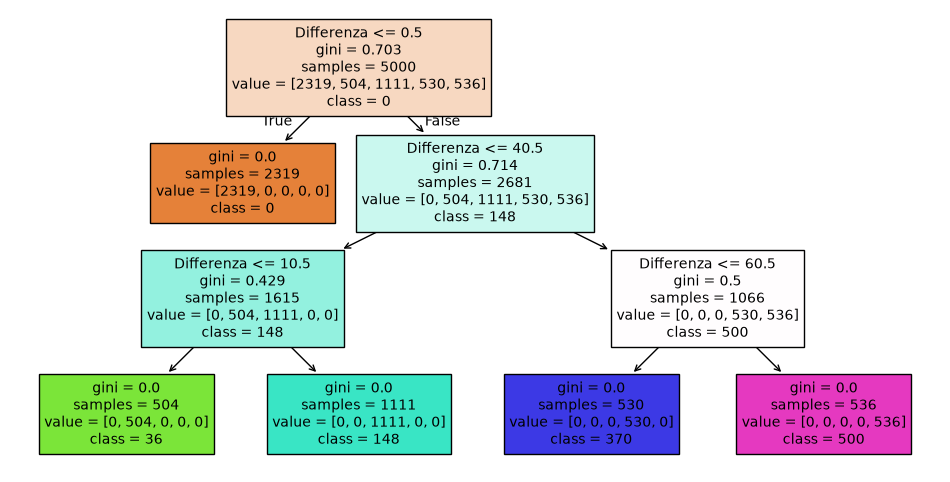

In [11]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plot_tree(albero, feature_names=["Differenza"],
          class_names=["0", "36", "148", "370", "500"], filled=True, fontsize=10)
plt.show()

In [12]:
# Multe per cinque auto nuove
nuove = pd.DataFrame({"Differenza": [5, 10, 11, 45, 70]})
albero.predict(nuove)

array([ 36,  36, 148, 370, 500])

In [13]:
# Su tutte le 5.000 auto l'albero dà la stessa multa della legge?
(albero.predict(X) == y).mean()

np.float64(1.0)

## 5. Training e test

Attenzione: l'albero ha preso il 100 % **sulle stesse multe da cui ha imparato**. È come un esame con le stesse domande dell'esercitazione: un voto alto non dimostra di aver capito.

Per sapere se un modello ha imparato davvero bisogna metterlo alla prova su esempi che **non ha mai visto**. Si dividono i dati in due parti:

- **training**: gli esempi da cui il modello impara;
- **test**: gli esempi tenuti da parte, solo per misurare quanto sbaglia.

Proviamo con un albero che ha visto solo **30 multe**; le altre 4.970 fanno da test.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=30, random_state=1)
len(X_train), len(X_test)

(30, 4970)

In [15]:
albero_30 = DecisionTreeClassifier(random_state=1)
albero_30.fit(X_train, y_train)

print(export_text(albero_30, feature_names=["Differenza"]))

|--- Differenza <= -3.50
|   |--- class: 0
|--- Differenza >  -3.50
|   |--- Differenza <= 40.00
|   |   |--- Differenza <= 12.00
|   |   |   |--- class: 36
|   |   |--- Differenza >  12.00
|   |   |   |--- class: 148
|   |--- Differenza >  40.00
|   |   |--- Differenza <= 65.00
|   |   |   |--- class: 370
|   |   |--- Differenza >  65.00
|   |   |   |--- class: 500



In [16]:
# L'accuracy è la quota di multe indovinate
albero_30.score(X_train, y_train), albero_30.score(X_test, y_test)

(1.0, 0.9261569416498994)

Sul training l'albero ha il **100 %**: le sue 30 multe le sa a memoria. Sul test scende al **92,6 %**: su 4.970 auto nuove ne sbaglia 367. E le soglie non sono quelle della legge: −3,5 · 12 · 40 · 65 invece di 0 · 10 · 40 · 60. Con 30 esempi non poteva sapere dove passa esattamente il confine: mette la soglia a metà strada tra gli esempi che ha.

In [17]:
# Dove sbaglia? Le multe del test indovinate male
test = X_test.copy()
test["vera"] = y_test
test["prevista"] = albero_30.predict(X_test)

sbagliate = test[test["vera"] != test["prevista"]]
sbagliate.groupby(["vera", "prevista"])["Differenza"].agg(["count", "min", "max"])

,,count,min,max
vera,prevista,,,
0,36,182,-3,0
148,36,89,11,12
500,370,96,61,65


Gli errori stanno tutti vicino ai confini:

- **182** auto tra 3 km/h sotto il limite e il limite stesso prendono una multa da 36 € senza aver superato il limite;
- **89** auto a 11–12 km/h oltre il limite pagano 36 € invece di 148 €;
- **96** auto tra 61 e 65 km/h oltre pagano 370 € invece di 500 €.

Lontano dalle soglie l'albero non sbaglia mai. È quello che succede a qualunque modello: dove ha visto pochi esempi, indovina.

### Con più esempi, soglie migliori

Ripetiamo con 10, 20, 30, … fino a 3.500 multe nel training (il 70 % del file), e ogni volta misuriamo l'accuracy sul test.

In [18]:
risultati = []
for n in [10, 20, 30, 50, 100, 200, 500, 1000, 3500]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=n, random_state=1)
    albero_n = DecisionTreeClassifier(random_state=1).fit(X_train, y_train)
    risultati.append({"multe_training": n,
                      "accuracy_training": albero_n.score(X_train, y_train),
                      "accuracy_test": albero_n.score(X_test, y_test)})

risultati = pd.DataFrame(risultati)
risultati

,multe_training,accuracy_training,accuracy_test
0,10,1.0,0.836673
1,20,1.0,0.936345
2,30,1.0,0.926157
3,50,1.0,0.932727
4,100,1.0,0.969184
5,200,1.0,0.992917
6,500,1.0,1.000000
7,1000,1.0,1.000000
8,3500,1.0,1.000000


In Python esiste anche ggplot: il pacchetto si chiama **plotnine** e la grammatica è la stessa (i nomi delle colonne vanno tra virgolette, e il grafico intero tra parentesi).

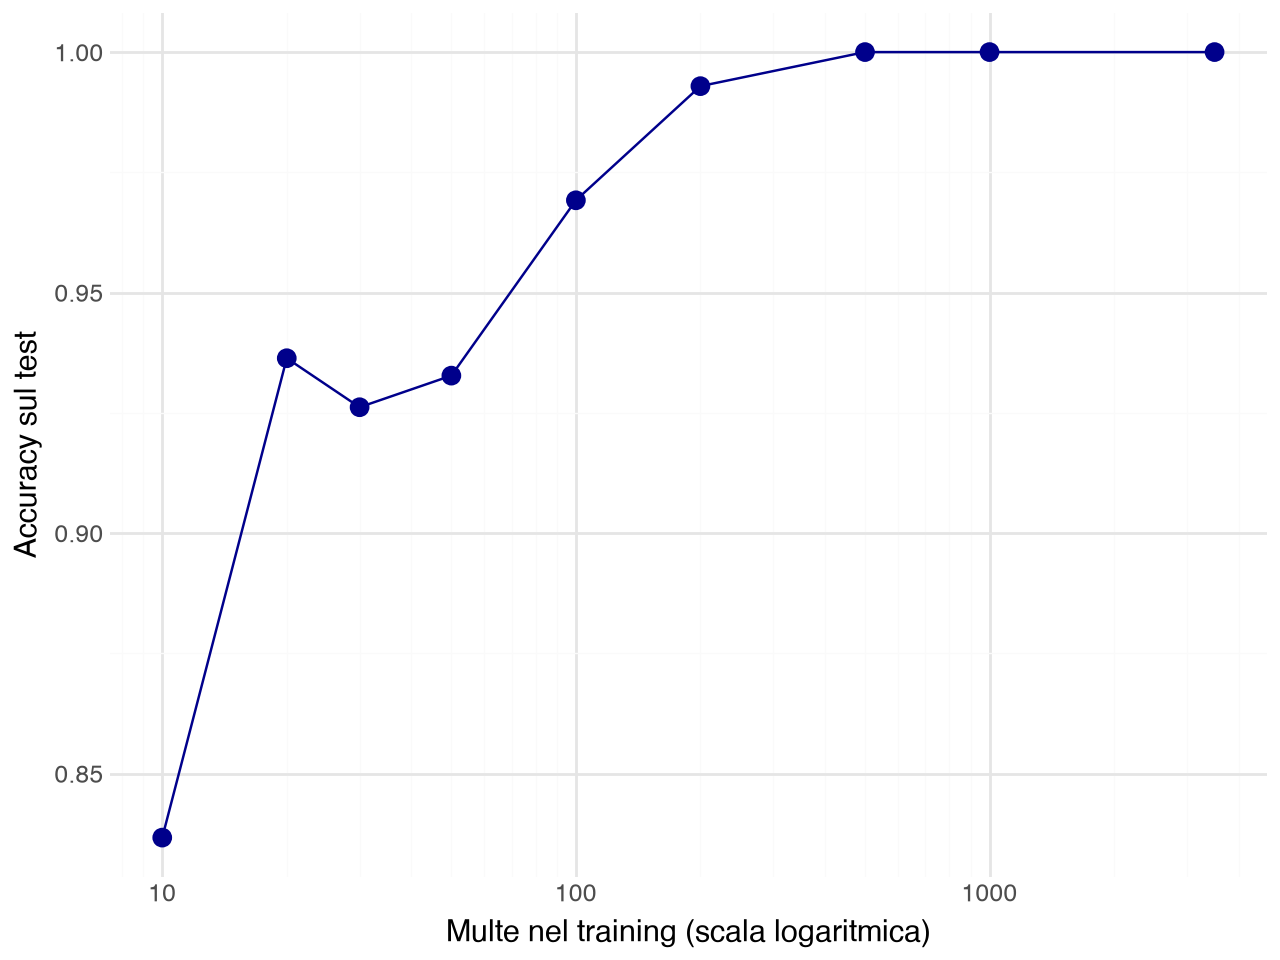

In [19]:
from plotnine import ggplot, aes, geom_line, geom_point, scale_x_log10, theme_minimal, labs

(ggplot(risultati, aes(x="multe_training", y="accuracy_test"))
 + geom_line(color="darkblue")
 + geom_point(color="darkblue", size=3)
 + scale_x_log10()
 + theme_minimal()
 + labs(x="Multe nel training (scala logaritmica)", y="Accuracy sul test"))

Con 10 multe l'albero indovina l'84 % delle altre; con 100 il 97 %; da 500 in su il 100 %. L'accuracy sul training è sempre 1, qualunque sia il numero di esempi: per questo non dice niente.

## Cosa abbiamo imparato

1. Un albero di classificazione trova da solo le soglie di una regola, guardando esempi già classificati.
2. In scikit-learn ogni modello si usa così: `fit(X_train, y_train)`, poi `predict` o `score` su dati nuovi.
3. L'accuracy sul training non dice niente: il modello quei dati li ha già visti. Conta solo quella sul **test**.
4. Con pochi esempi le soglie sono approssimative, e una multa che nel training non c'è non verrà mai prevista.

Adesso il lab: `lab_multe.ipynb`.